In [100]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score,mean_absolute_error
from sklearn.preprocessing import StandardScaler
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 110
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [101]:
data = pd.read_csv('auto-mpg.csv', na_values='?')
data.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130.0,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,1,ford torino


In [102]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    str    
dtypes: float64(4), int64(4), str(1)
memory usage: 28.1 KB


In [103]:
df_clean = (data.drop(columns=['origin', 'car name', 'cylinders'])
            .dropna()
            .reset_index(drop=True))

df_clean.head()


,mpg,displacement,horsepower,weight,acceleration,model year
0,18.0,307.0,130.0,3504,12.0,70
1,15.0,350.0,165.0,3693,11.5,70
2,18.0,318.0,150.0,3436,11.0,70
3,16.0,304.0,150.0,3433,12.0,70
4,17.0,302.0,140.0,3449,10.5,70


In [104]:
TARGET = 'mpg'
quantity_features = ['displacement', 'horsepower', 'weight', 'acceleration', 'model year']

In [105]:
df_clean[quantity_features]

,displacement,horsepower,weight,acceleration,model year
0,307.0,130.0,3504,12.0,70
1,350.0,165.0,3693,11.5,70
2,318.0,150.0,3436,11.0,70
3,304.0,150.0,3433,12.0,70
4,302.0,140.0,3449,10.5,70
...,...,...,...,...,...
387,140.0,86.0,2790,15.6,82
388,97.0,52.0,2130,24.6,82
389,135.0,84.0,2295,11.6,82
390,120.0,79.0,2625,18.6,82


In [106]:
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
mpg,392.0,23.445918,7.805007,9.0,17.000,22.75,29.000,46.6
displacement,392.0,194.411990,104.644004,68.0,105.000,151.00,275.750,455.0
horsepower,392.0,104.469388,38.491160,46.0,75.000,93.50,126.000,230.0
weight,392.0,2977.584184,849.402560,1613.0,2225.250,2803.50,3614.750,5140.0
acceleration,392.0,15.541327,2.758864,8.0,13.775,15.50,17.025,24.8
model year,392.0,75.979592,3.683737,70.0,73.000,76.00,79.000,82.0


In [107]:
## Variable Types

##1. Quantitative Variable(wieght, height, age, salary, etc.)
##   1.1. Continuous Variable
##   1.2. Discrete Variable
##2. qualitative Variable(gender, color, nationality, etc.)   

In [108]:
#EDA

##1. Univarite Analysis
##2. Bivariate Analysis
##3. Multivariate Analysis
##4. Correlation Analysis

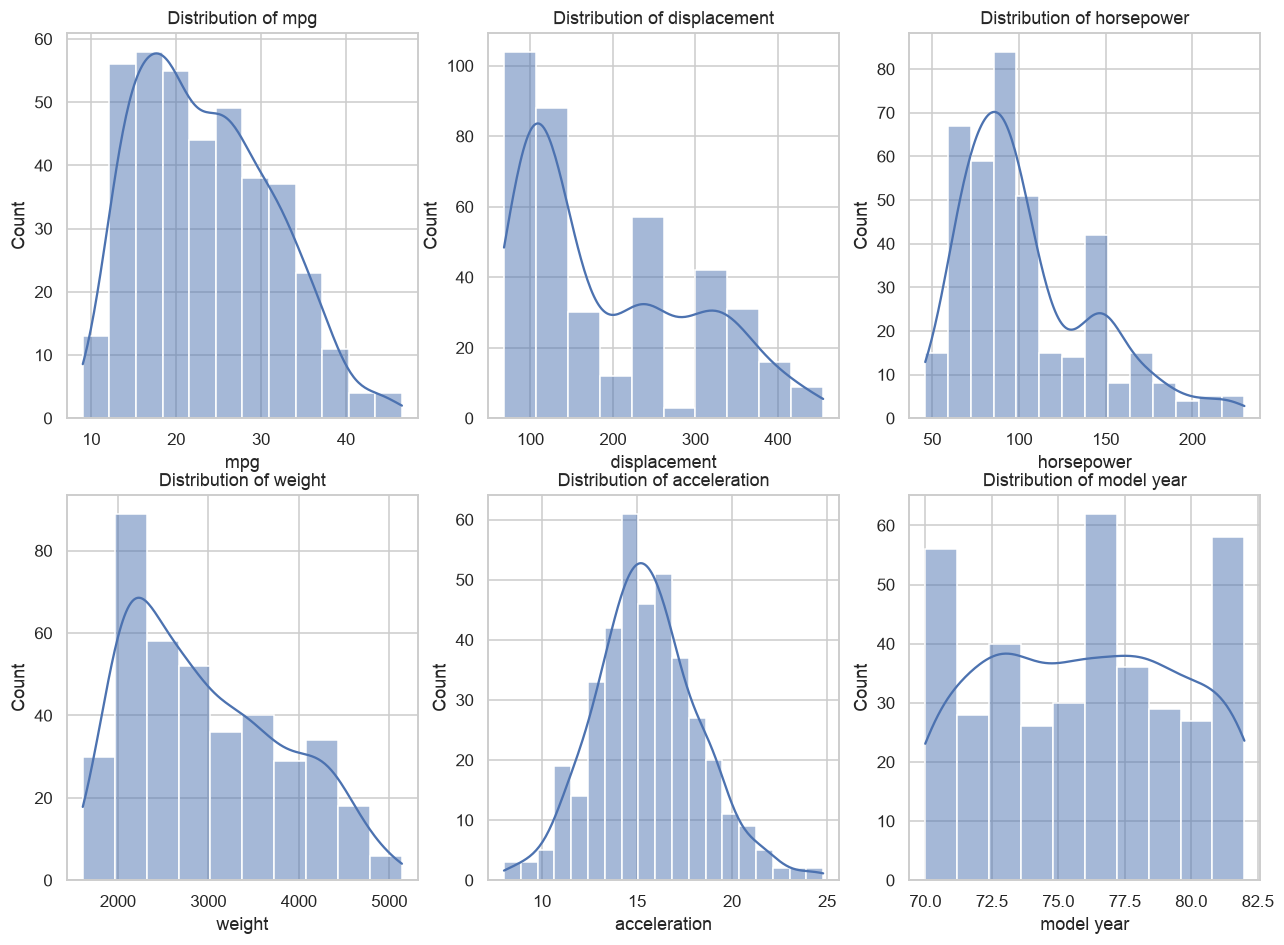

In [109]:
#univariate Analysis
cols = [TARGET] + quantity_features

fig, axes = plt.subplots(2, 3, figsize=(14, 10))
axes = axes.ravel()
for i, c in enumerate(cols):
    sns.histplot(df_clean[c], ax=axes[i], kde=True)
    axes[i].set_title(f'Distribution of {c}')
plt.show()


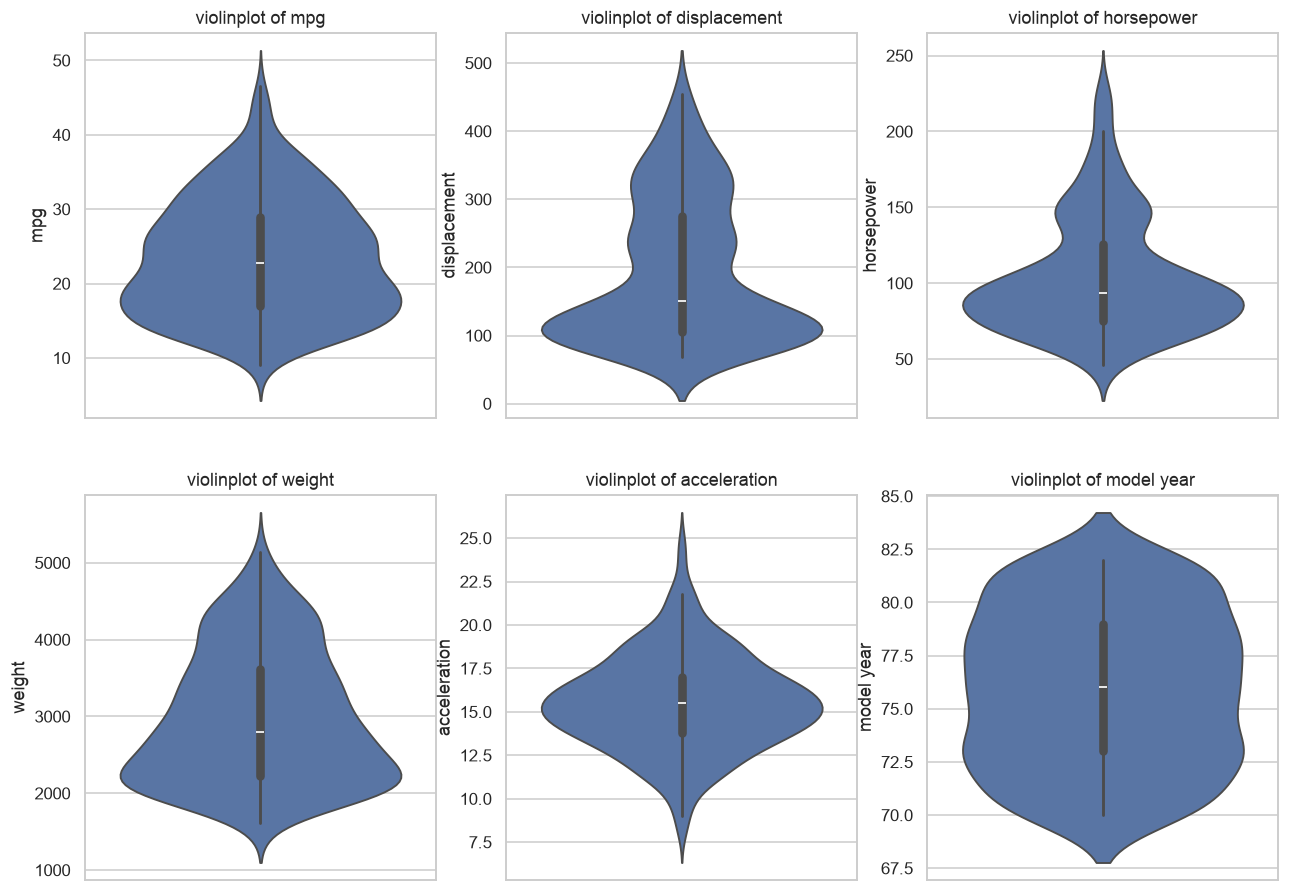

In [110]:


fig, axes = plt.subplots(2, 3, figsize=(14, 10))
axes = axes.ravel()
for i, c in enumerate(cols):
    sns.violinplot(data=df_clean[c], ax=axes[i])
    axes[i].set_title(f'violinplot of {c}')
plt.show()


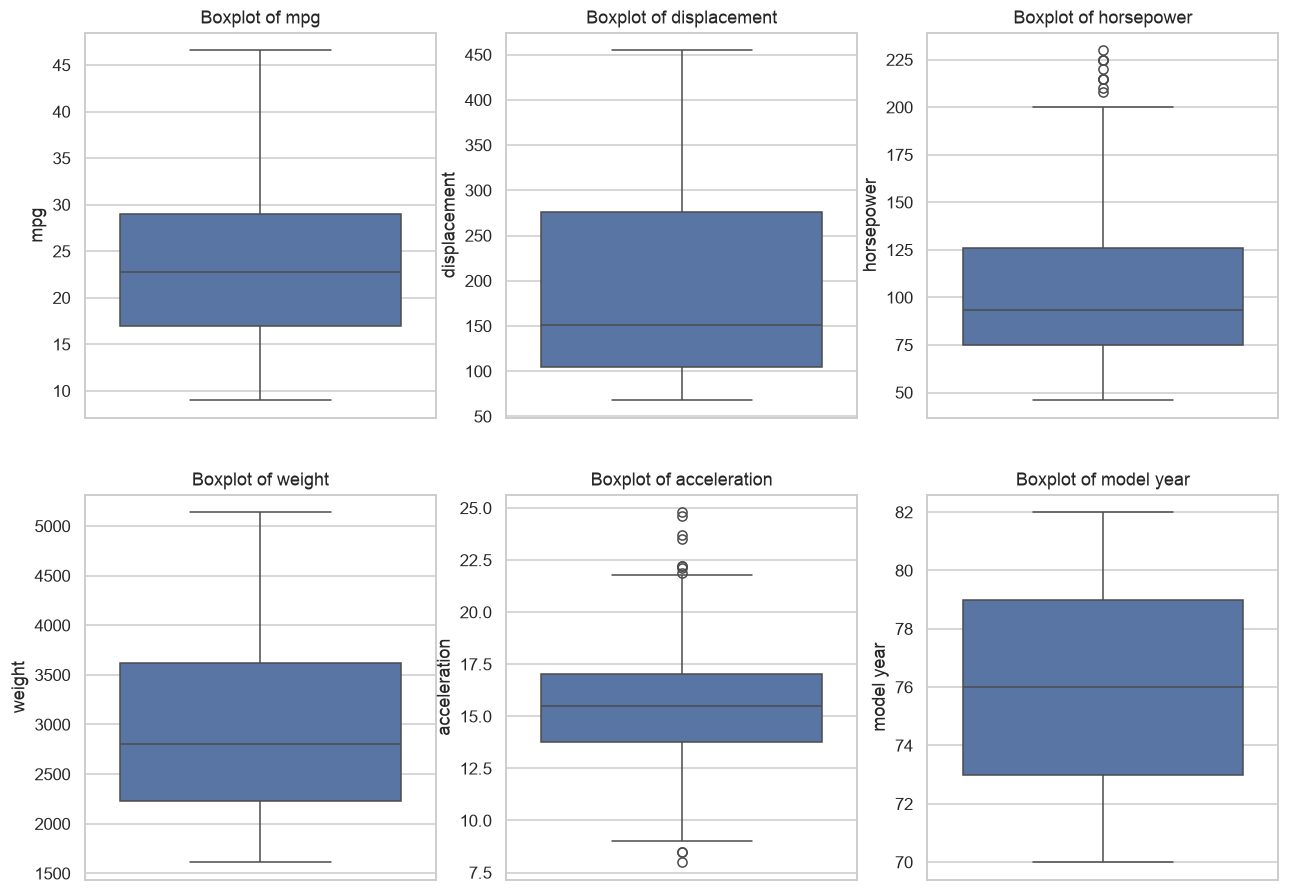

In [111]:
fig, axes = plt.subplots(2, 3, figsize=(14, 10))
axes = axes.ravel()
for i, c in enumerate(cols):
    sns.boxplot(data=df_clean[c], ax=axes[i])
    axes[i].set_title(f'Boxplot of {c}')
plt.show()

In [112]:
df_clean.head()

,mpg,displacement,horsepower,weight,acceleration,model year
0,18.0,307.0,130.0,3504,12.0,70
1,15.0,350.0,165.0,3693,11.5,70
2,18.0,318.0,150.0,3436,11.0,70
3,16.0,304.0,150.0,3433,12.0,70
4,17.0,302.0,140.0,3449,10.5,70


In [113]:
df_clean.skew(numeric_only=True).sort_values(ascending=False)


horsepower      1.087326
displacement    0.701669
weight          0.519586
mpg             0.457092
acceleration    0.291587
model year      0.019688
dtype: float64

In [114]:
#bivariate Analysis

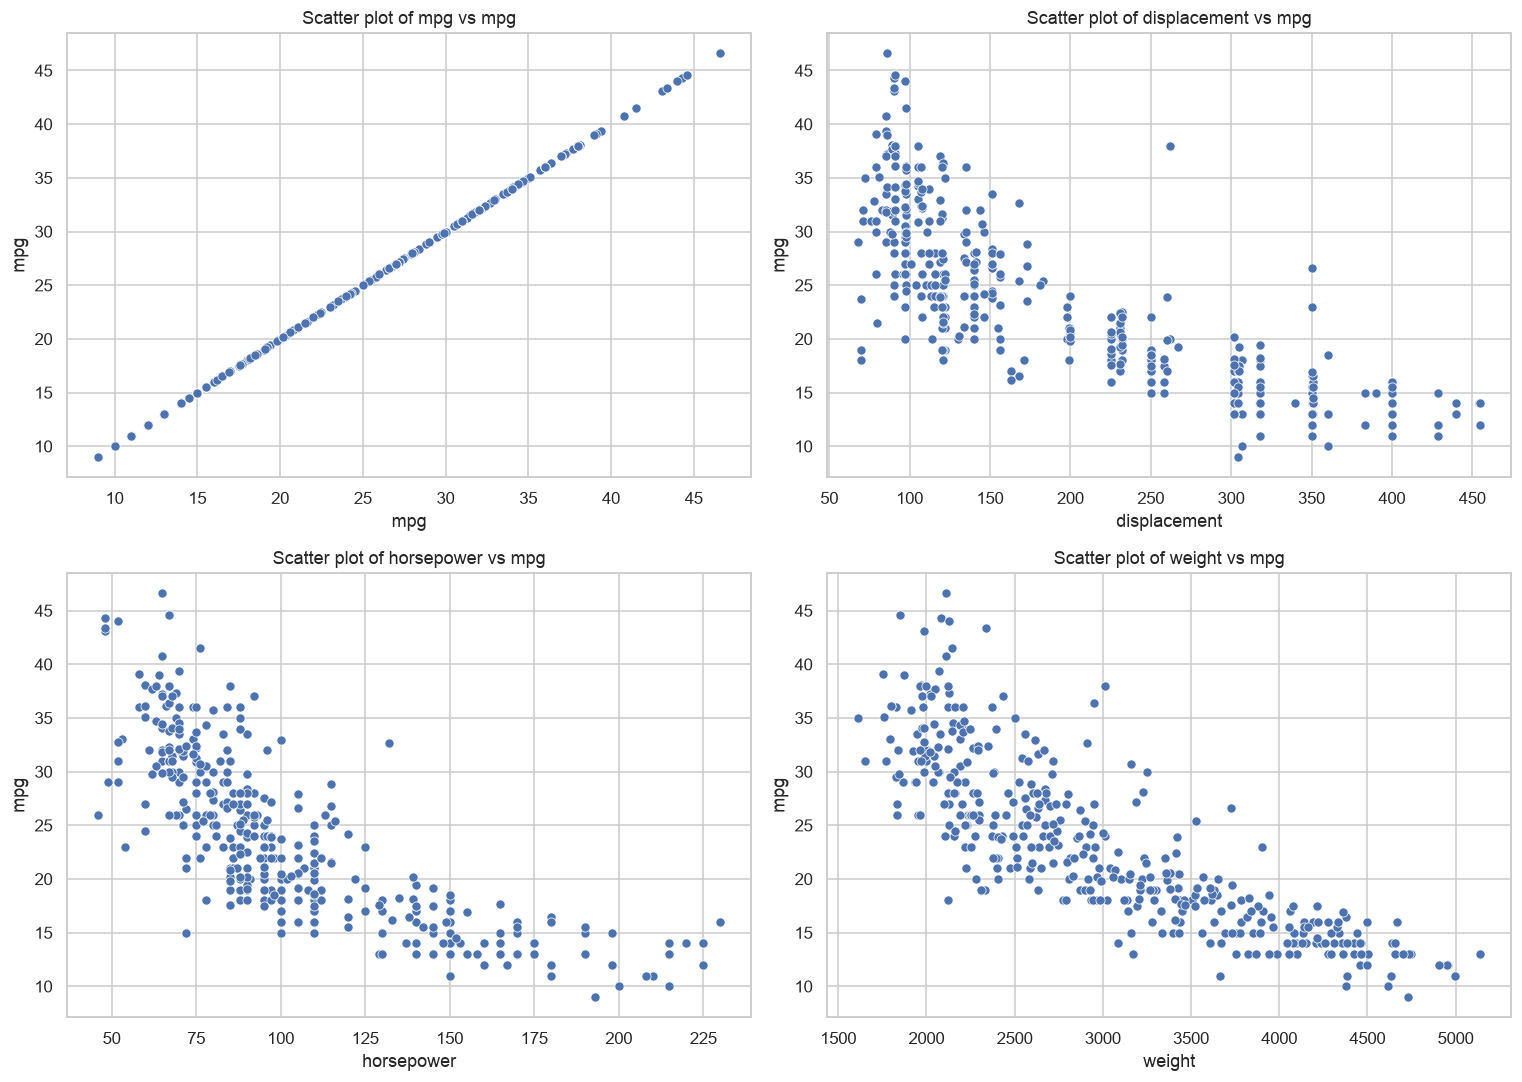

In [115]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))    
axes = axes.ravel()
for i, c in enumerate(cols[:4]):
    sns.scatterplot(data=df_clean, x=c, y=TARGET, ax=axes[i])
    axes[i].set_title(f'Scatter plot of {c} vs {TARGET}')
plt.tight_layout() 
plt.show()

In [116]:
print("target type:", df_clean[TARGET].dtype)
print("feature types:", df_clean[cols[:4]].dtypes)

target type: float64
feature types: mpg             float64
displacement    float64
horsepower      float64
weight            int64
dtype: object


In [149]:
for c in cols[:4]:
    df_clean[c] = pd.to_numeric(df_clean[c], errors='coerce')

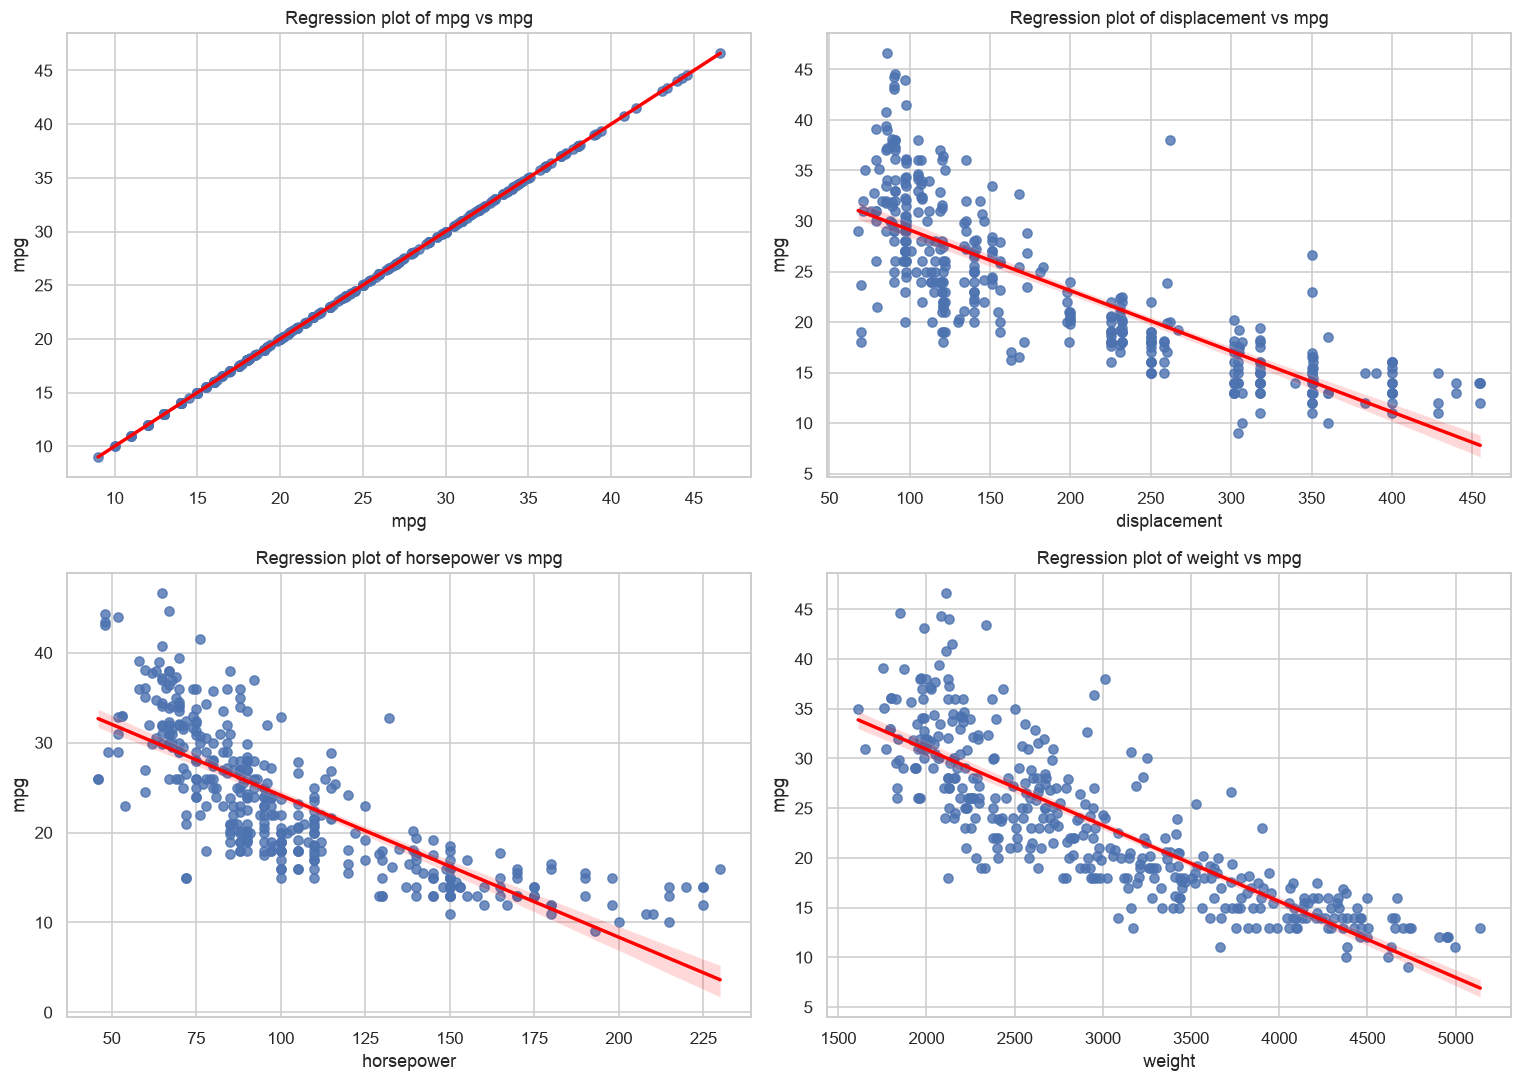

In [150]:
fig, axes = plt.subplots(2,2, figsize=(14, 10))
axes = axes.ravel()
for i, c in enumerate(cols[:4]):
    sns.regplot(data=df_clean, x=c, y=TARGET, ax=axes[i],line_kws={"color": "red"})
    axes[i].set_title(f'Regression plot of {c} vs {TARGET}'
    )
plt.tight_layout()
plt.show()

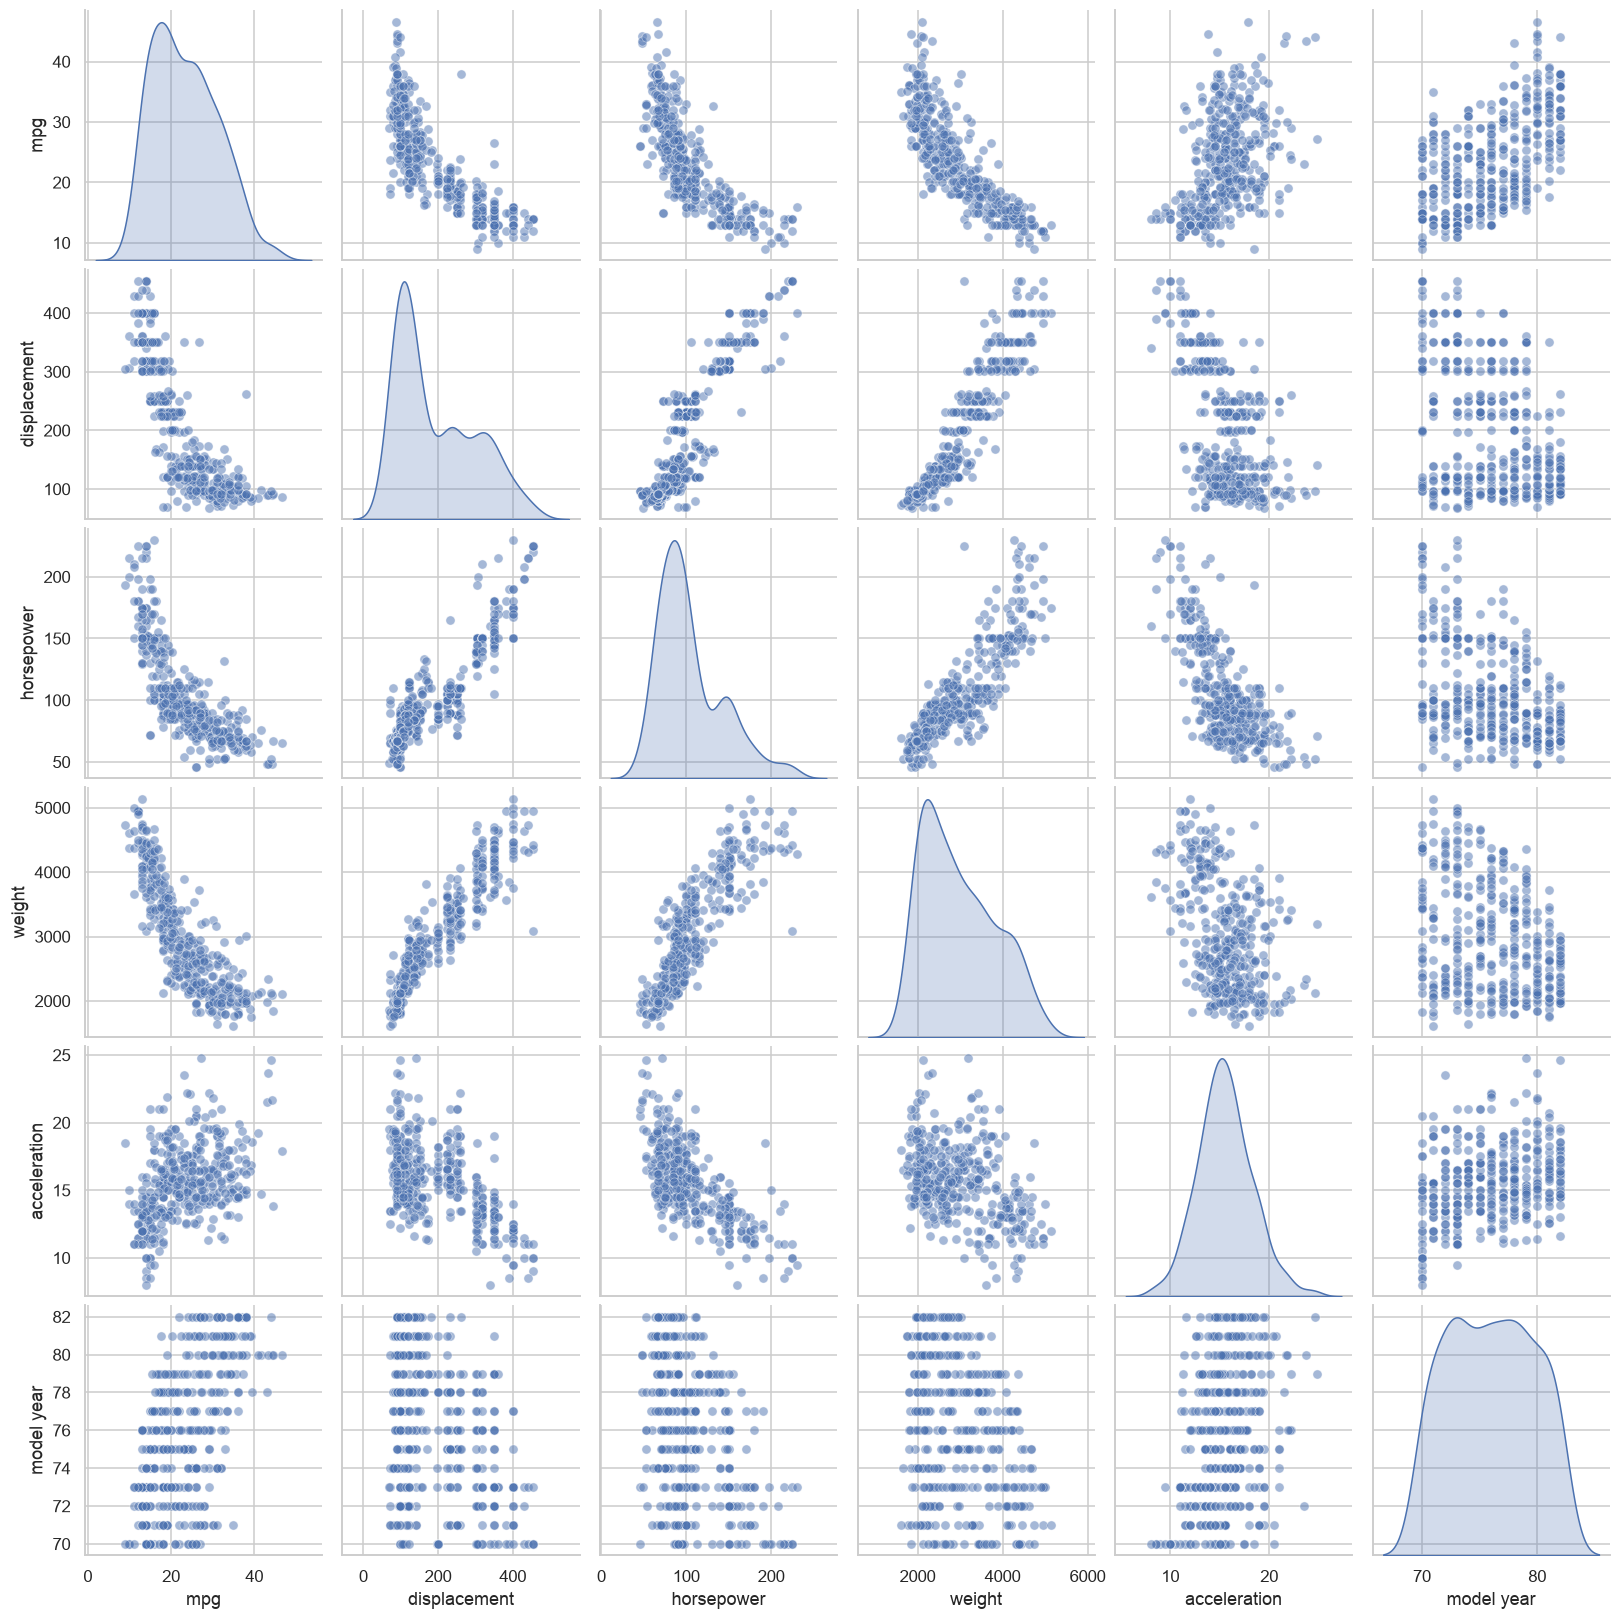

In [119]:
sns.pairplot(df_clean[cols], diag_kind='kde', plot_kws={'alpha': 0.5})

In [120]:
##correlation Analysis


,mpg,displacement,horsepower,weight,acceleration,model year
mpg,1.000000,-0.805127,-0.778427,-0.832244,0.423329,0.580541
displacement,-0.805127,1.000000,0.897257,0.932994,-0.543800,-0.369855
horsepower,-0.778427,0.897257,1.000000,0.864538,-0.689196,-0.416361
weight,-0.832244,0.932994,0.864538,1.000000,-0.416839,-0.309120
acceleration,0.423329,-0.543800,-0.689196,-0.416839,1.000000,0.290316
model year,0.580541,-0.369855,-0.416361,-0.309120,0.290316,1.000000


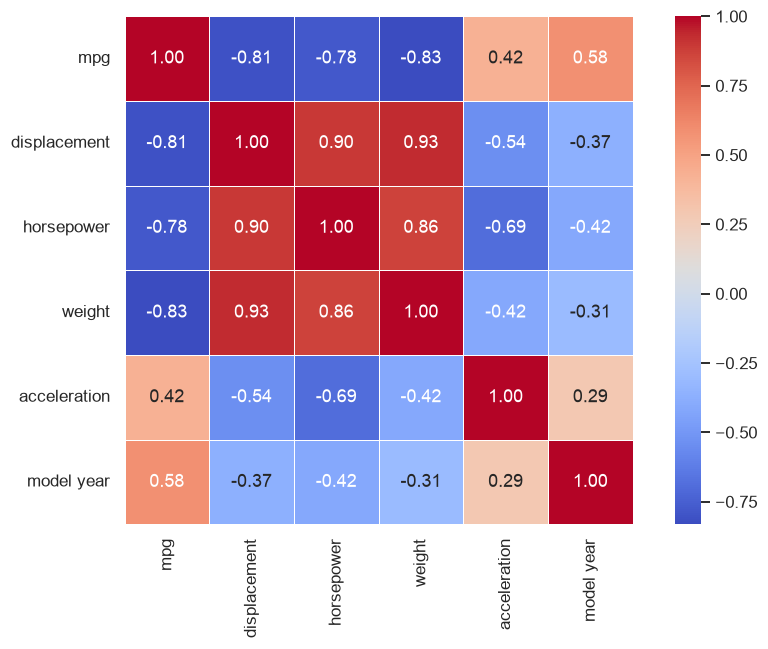

In [121]:
plt.figure(figsize=(10, 6))
sns.heatmap(df_clean.corr(),annot=True, fmt=".2f", cmap='coolwarm', cbar=True, square=True, linewidths=0.5)
df_clean.corr()

In [122]:
#multicolinearity
#having x variables wich are correlated with each other

##Linear Regression 

##1. Normally distributed data(x variables and y variable)
##2. No multicollinearity



In [123]:
##Linear Regression Model

In [124]:
df_clean.head()

,mpg,displacement,horsepower,weight,acceleration,model year
0,18.0,307.0,130.0,3504,12.0,70
1,15.0,350.0,165.0,3693,11.5,70
2,18.0,318.0,150.0,3436,11.0,70
3,16.0,304.0,150.0,3433,12.0,70
4,17.0,302.0,140.0,3449,10.5,70


In [125]:
X = df_clean[quantity_features]
Y = df_clean[TARGET]

In [126]:
train_size = 0.8
test_size = 0.2


In [127]:
train_X, test_X, train_Y, test_Y = train_test_split(X, Y, train_size=train_size, test_size=test_size, random_state=RANDOM_STATE)

In [128]:
train_X.shape, test_X.shape, train_Y.shape, test_Y.shape

((313, 5), (79, 5), (313,), (79,))

In [129]:
model = LinearRegression()
model.fit(train_X, train_Y)



,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[-0. ,-0. ,-0.01, 0.06, 0.76]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['displacement','horsepower','weight','acceleration','model year']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-15.35
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [132]:
model.coef_.tolist() 

[-0.0007273556359975735,
 -0.0019738607827804004,
 -0.00658217356801709,
 0.06244776816477723,
 0.7608698185842151]

In [133]:
model.intercept_

np.float64(-15.351591282480566)

array([25.94069501, 26.26450538, 32.98786453, 26.87783614, 29.37807295,
       29.09548123,  7.55404471, 29.24471794, 20.87742308, 28.97453954,
       12.44003156, 23.83004234, 16.42879648, 28.20431753, 22.15663498,
       30.86198437, 21.23372787, 31.63328468, 27.87351859, 29.74308445,
       19.89840552, 34.38272498, 34.01200188, 15.11483297, 28.81019922,
       26.00229443, 20.78146351, 16.63110094, 28.50671906, 23.7892342 ,
       12.82227894, 23.59518505, 21.52416864, 29.84428245, 10.97143451,
       34.72151338, 10.92781666, 26.27012067, 11.67034473,  7.72060566,
       12.85165705, 27.83199225, 34.74004299, 26.49475409, 11.35607445,
        8.96782253, 17.62496372, 31.45269112, 25.36189045, 30.40797077,
       11.61355918, 25.13507671, 24.45658803, 33.46674915, 28.90743505,
       17.76559828, 20.94781706, 23.16622304, 23.10630798, 24.60964392,
        7.5154241 , 22.92119621, 27.43800545, 23.0507875 , 28.08133258,
       28.67320091, 26.77890855, 29.6346114 , 22.40894377,  9.25

In [135]:
coefficients = pd.DataFrame({'Feature':quantity_features, 'Coefficient':model.coef_})

In [136]:
coefficients

,Feature,Coefficient
0,displacement,-0.000727
1,horsepower,-0.001974
2,weight,-0.006582
3,acceleration,0.062448
4,model year,0.760870


In [139]:
y_pred = model.predict(test_X)
y_pred

array([25.94069501, 26.26450538, 32.98786453, 26.87783614, 29.37807295,
       29.09548123,  7.55404471, 29.24471794, 20.87742308, 28.97453954,
       12.44003156, 23.83004234, 16.42879648, 28.20431753, 22.15663498,
       30.86198437, 21.23372787, 31.63328468, 27.87351859, 29.74308445,
       19.89840552, 34.38272498, 34.01200188, 15.11483297, 28.81019922,
       26.00229443, 20.78146351, 16.63110094, 28.50671906, 23.7892342 ,
       12.82227894, 23.59518505, 21.52416864, 29.84428245, 10.97143451,
       34.72151338, 10.92781666, 26.27012067, 11.67034473,  7.72060566,
       12.85165705, 27.83199225, 34.74004299, 26.49475409, 11.35607445,
        8.96782253, 17.62496372, 31.45269112, 25.36189045, 30.40797077,
       11.61355918, 25.13507671, 24.45658803, 33.46674915, 28.90743505,
       17.76559828, 20.94781706, 23.16622304, 23.10630798, 24.60964392,
        7.5154241 , 22.92119621, 27.43800545, 23.0507875 , 28.08133258,
       28.67320091, 26.77890855, 29.6346114 , 22.40894377,  9.25

In [145]:
eval = rmse(test_Y, y_pred)
eval

np.float64(3.2524882561812007)

In [146]:
mse = mean_squared_error(test_Y, y_pred)
mse

10.578679856596628

In [147]:
mae = mean_absolute_error(test_Y, y_pred)
mae

2.5132563184338874